1. Write a Python program to perform Exploratory Data Analysis (EDA) and develop a
Linear Regression model using the UCI Student Performance dataset.

In [21]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [22]:
#Load the dataset
df = pd.read_excel('student-mat.xlsx')
features = ['studytime', 'failures', 'absences', 'G1', 'G2']
target = 'G3'
data = df[features + [target]]
print("Target variable:", target)
print(data.head())

Target variable: G3
   studytime  failures  absences  G1  G2  G3
0          2         0         6   5   6   6
1          2         0         4   5   5   6
2          2         3        10   7   8  10
3          3         0         2  15  14  15
4          2         0         4   6  10  10



Correlation matrix:
            studytime  failures  absences        G1        G2        G3
studytime   1.000000 -0.173563 -0.062700  0.160612  0.135880  0.097820
failures   -0.173563  1.000000  0.063726 -0.354718 -0.355896 -0.360415
absences   -0.062700  0.063726  1.000000 -0.031003 -0.031777  0.034247
G1          0.160612 -0.354718 -0.031003  1.000000  0.852118  0.801468
G2          0.135880 -0.355896 -0.031777  0.852118  1.000000  0.904868
G3          0.097820 -0.360415  0.034247  0.801468  0.904868  1.000000


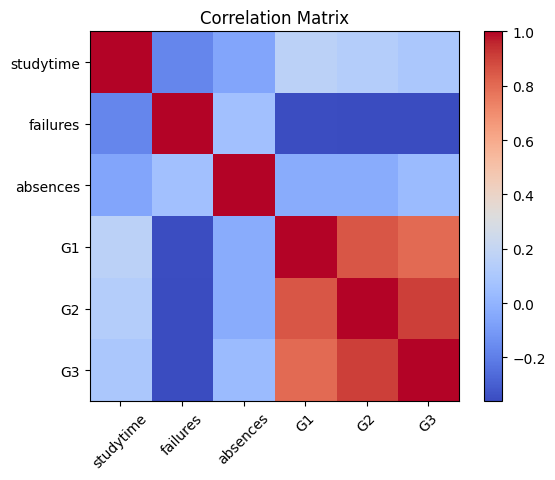


Feature most correlated with G3: G2


In [23]:
# (b) Correlation matrix
corr = data.corr()
print("\nCorrelation matrix:\n", corr)

plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.title('Correlation Matrix')
plt.show()

best_feature = corr['G3'].drop('G3').abs().idxmax()
print("\nFeature most correlated with G3:", best_feature)

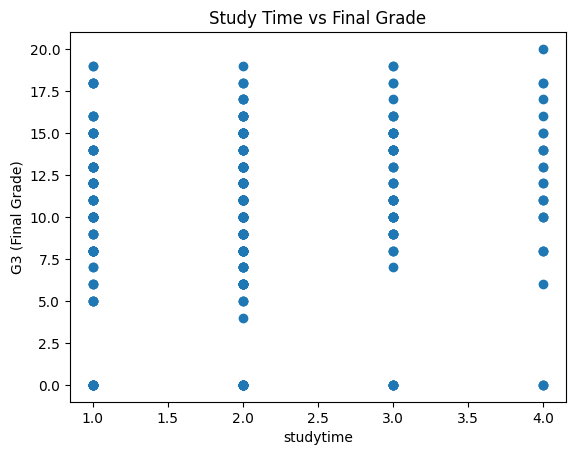

In [24]:
# (c) Scatter plot: study time vs final grade
plt.scatter(data['studytime'], data['G3'])
plt.xlabel('studytime')
plt.ylabel('G3 (Final Grade)')
plt.title('Study Time vs Final Grade')
plt.show()

In [25]:
# (d) Train-test split (80% / 20%)
X = data[[best_feature]]
y = data['G3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
# (e) Train Linear Regression on the most influential feature
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [27]:
# (f) Evaluate with Mean Squared Error
y_pred = model.predict(X_test)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Mean Squared Error: 4.216183766505532
